# Stage 2 — Residual-attentive collocation enrichment

Python/Jupyter conversion of `STAGE_02_INF_RBF_SPP_PAPER.m`. Run the Stage 1 notebook first so `STAGE_01_INF_RBF_SPP_attention_PAPER.npz` exists in the same working directory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
from pathlib import Path
from time import perf_counter

np.set_printoptions(precision=6, suppress=True)

def radical_inverse(n, b):
    n = np.asarray(n, dtype=int).copy()
    r = np.zeros_like(n, dtype=float)
    f = 1.0 / b
    while np.any(n > 0):
        r += f * (n % b)
        n //= b
        f /= b
    return r

def exact_solution_spp(x, nu):
    x = np.asarray(x, dtype=float).reshape(-1)
    em = np.exp(-1.0 / nu)
    u = (np.exp((x - 1.0) / nu) - em) / (1.0 - em)
    u[np.isclose(x, 0.0)] = 0.0
    u[np.isclose(x, 1.0)] = 1.0
    return u

def kernel_raw(cfg, x, y, type1, type2):
    sigma = cfg['sigma_x']
    a = cfg['cx_a']
    b = cfg['cx_b']
    nu = cfg['nu']

    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)

    m = 0.5 * (x + y)
    d = x - y
    h = 0.5 * d

    za = a - m
    zb = b - m

    Ed = np.exp(-(d**2) / (4.0 * sigma**2))
    ea = np.exp(-(za / sigma)**2)
    eb = np.exp(-(zb / sigma)**2)

    I0 = 0.5 * sigma * np.sqrt(np.pi) * (erf(zb / sigma) - erf(za / sigma))
    I1 = 0.5 * sigma**2 * (ea - eb)
    I2 = 0.5 * sigma**2 * (za * ea - zb * eb) + 0.5 * sigma**2 * I0
    I3 = 0.5 * sigma**2 * (za**2 * ea - zb**2 * eb) + sigma**2 * I1
    I4 = 0.5 * sigma**2 * (za**3 * ea - zb**3 * eb) + 1.5 * sigma**2 * I2

    C = 1.0 / (b - a)

    if type1 == 'val' and type2 == 'val':
        return C * Ed * I0

    px0 = -h / sigma**2 - nu * h**2 / sigma**4 + nu / sigma**2
    px1 = 1.0 / sigma**2 + 2.0 * nu * h / sigma**4
    px2 = -nu / sigma**4

    py0 = h / sigma**2 - nu * h**2 / sigma**4 + nu / sigma**2
    py1 = 1.0 / sigma**2 - 2.0 * nu * h / sigma**4
    py2 = -nu / sigma**4

    if type1 == 'pde' and type2 == 'val':
        return C * Ed * (px0 * I0 + px1 * I1 + px2 * I2)
    if type1 == 'val' and type2 == 'pde':
        return C * Ed * (py0 * I0 + py1 * I1 + py2 * I2)
    if type1 == 'pde' and type2 == 'pde':
        c0 = px0 * py0
        c1 = px0 * py1 + px1 * py0
        c2 = px0 * py2 + px1 * py1 + px2 * py0
        c3 = px1 * py2 + px2 * py1
        c4 = px2 * py2
        return C * Ed * (c0 * I0 + c1 * I1 + c2 * I2 + c3 * I3 + c4 * I4)
    raise ValueError('Unknown kernel functional type.')

def compute_kernel_norm(cfg):
    xr = 0.5 * (cfg['XL'] + cfg['XR'])
    return float(kernel_raw(cfg, [xr], [xr], 'val', 'val')[0, 0])

def kernel_1d(cfg, x, y, type1, type2):
    return kernel_raw(cfg, x, y, type1, type2) / cfg['norm_const']

def predict_value(cfg, xP, xB, wP, wB, a, xq):
    NP = len(xP)
    aP = a[:NP]
    aB = a[NP:]
    KP = kernel_1d(cfg, xq, xP, 'val', 'pde')
    KB = kernel_1d(cfg, xq, xB, 'val', 'val')
    return (wP * KP) @ aP + (wB * KB) @ aB

def solve_inf_rbf_spp(cfg, xP, xB, uB, ridge_rel, eig_tol_rel):
    Np, Nb = len(xP), len(xB)
    wP, wB = 1 / np.sqrt(Np), 1 / np.sqrt(Nb)

    _t0 = perf_counter()
    KPP = kernel_1d(cfg, xP, xP, 'pde', 'pde')
    KPB = kernel_1d(cfg, xP, xB, 'pde', 'val')
    KBB = kernel_1d(cfg, xB, xB, 'val', 'val')
    K = np.block([[wP*wP*KPP, wP*wB*KPB], [wB*wP*KPB.T, wB*wB*KBB]])
    K = 0.5 * (K + K.T)
    rhs = np.concatenate([np.zeros(Np), wB * uB])
    t_assembly = perf_counter() - _t0

    _t0 = perf_counter()
    d, V = np.linalg.eigh(K)
    dmax = np.max(d)
    if dmax <= 0:
        raise ValueError('Kernel Gram matrix is not positive on the retained scale.')
    lam = ridge_rel * dmax
    keep = d > eig_tol_rel * dmax
    Vuse = V[:, keep]
    duse = d[keep] + lam
    coeff = Vuse @ ((Vuse.T @ rhs) / duse)
    dkeep = d[keep]
    cond_eff = np.max(dkeep + lam) / np.min(dkeep + lam)
    t_solve = perf_counter() - _t0

    return dict(coeff=coeff, rank=int(np.sum(keep)), lambda_=float(lam),
                wP=float(wP), wB=float(wB), cond_eff=float(cond_eff),
                t_assembly=float(t_assembly), t_solve=float(t_solve),
                t_total=float(t_assembly + t_solve))


## Load Stage 1 results

In [2]:
stage1_file = Path('STAGE_01_INF_RBF_SPP_attention_PAPER.npz')
if not stage1_file.exists():
    raise FileNotFoundError('Run the Stage 1 notebook first.')
D = np.load(stage1_file)

def scalar(name, cast=float): return cast(D[name].item())
XL, XR, L, nu = map(scalar, ['XL','XR','L','nu'])
NBx = scalar('NBx', int)
x_edges = D['x_edges']
Npde_per_block_pilot = scalar('Npde_per_block_pilot', int)
sigma_x, cx_a, cx_b = map(scalar, ['sigma_x','cx_a','cx_b'])
ridge_rel, eig_tol_rel = map(scalar, ['ridge_rel','eig_tol_rel'])
level_map = D['level_map'].astype(int)
attention_score = D['attention_score']
rmse_predictor = scalar('rmse_predictor')
maxerr_predictor = scalar('maxerr_predictor')

kcfg = dict(sigma_x=sigma_x, cx_a=cx_a, cx_b=cx_b, nu=nu, XL=XL, XR=XR)
kcfg['norm_const'] = compute_kernel_norm(kcfg)
xB = np.array([XL, XR]); uB = np.array([0.0, 1.0]); Nbc = 2

## Adaptive collocation levels and candidate bank

In [3]:
Npde_level = np.array([2, 8, 24], dtype=int)
Nmax_block = int(Npde_level[-1])
h01 = radical_inverse(np.arange(1, Nmax_block + 1), 2)
NPmax = NBx * Nmax_block
xPmax = np.zeros(NPmax)
block_id = np.zeros(NPmax, dtype=int)
local_id = np.zeros(NPmax, dtype=int)
kk = 0
for jx in range(NBx):
    xa, xb = x_edges[jx], x_edges[jx+1]
    ids = slice(kk, kk + Nmax_block)
    xPmax[ids] = xa + (xb - xa) * h01
    block_id[ids] = jx + 1
    local_id[ids] = np.arange(1, Nmax_block + 1)
    kk += Nmax_block

activeA = np.zeros(NPmax, dtype=bool)
for jx in range(NBx):
    nloc = Npde_level[level_map[jx] - 1]
    activeA |= ((block_id == jx + 1) & (local_id <= nloc))
idxA = np.flatnonzero(activeA)
xP_adapt = xPmax[idxA]
Np_adapt = len(xP_adapt)

xu = np.linspace(XL, XR, Np_adapt + 2)
xP_uniform = xu[1:-1]
Np_uniform = len(xP_uniform)

print('Attention blocks low/mid/high =', *(np.sum(level_map == k) for k in (1,2,3)))
print(f'Adaptive PDE points            = {Np_adapt}')
print(f'Uniform-reference PDE points   = {Np_uniform}')
print(f'Adaptive/uniform budget ratio  = {Np_adapt/Np_uniform:.4f}')

Attention blocks low/mid/high = 97 1 2
Adaptive PDE points            = 250
Uniform-reference PDE points   = 250
Adaptive/uniform budget ratio  = 1.0000


## Solve adaptive and budget-matched uniform systems

In [4]:
solA = solve_inf_rbf_spp(kcfg, xP_adapt, xB, uB, ridge_rel, eig_tol_rel)
solU = solve_inf_rbf_spp(kcfg, xP_uniform, xB, uB, ridge_rel, eig_tol_rel)
print(f'Adaptive retained modes        = {solA["rank"]} / {Np_adapt+Nbc}')
print(f'Uniform retained modes         = {solU["rank"]} / {Np_uniform+Nbc}')
print(f'Adaptive ridge lambda          = {solA["lambda_"]:.3e}')
print(f'Uniform ridge lambda           = {solU["lambda_"]:.3e}')
print(f'Adaptive effective cond.       = {solA["cond_eff"]:.3e}')
print(f'Uniform effective cond.        = {solU["cond_eff"]:.3e}')
print(f'Adaptive assembly time        = {solA["t_assembly"]:.6f} s')
print(f'Adaptive spectral solve time  = {solA["t_solve"]:.6f} s')
print(f'Adaptive total solve time     = {solA["t_total"]:.6f} s')
print(f'Uniform assembly time         = {solU["t_assembly"]:.6f} s')
print(f'Uniform spectral solve time   = {solU["t_solve"]:.6f} s')
print(f'Uniform total solve time      = {solU["t_total"]:.6f} s')


Adaptive retained modes        = 252 / 252
Uniform retained modes         = 252 / 252
Adaptive ridge lambda          = 2.113e-04
Uniform ridge lambda           = 5.600e-05
Adaptive effective cond.       = 5.369e+05
Uniform effective cond.        = 1.120e+05
Adaptive assembly time        = 0.009869 s
Adaptive spectral solve time  = 0.026960 s
Adaptive total solve time     = 0.036829 s
Uniform assembly time         = 0.021573 s
Uniform spectral solve time   = 0.040712 s
Uniform total solve time      = 0.062284 s


## Validation and budget-matched results

In [5]:
Nx_plot = 20001
x_plot = np.linspace(XL, XR, Nx_plot)
u_ex = exact_solution_spp(x_plot, nu)

_t0 = perf_counter()
u_adapt = predict_value(kcfg, xP_adapt, xB, solA['wP'], solA['wB'], solA['coeff'], x_plot)
t_stage2_prediction_adaptive = perf_counter() - _t0

_t0 = perf_counter()
u_uniform = predict_value(kcfg, xP_uniform, xB, solU['wP'], solU['wB'], solU['coeff'], x_plot)
t_stage2_prediction_uniform = perf_counter() - _t0
errA, errU = u_adapt - u_ex, u_uniform - u_ex
rmse_adaptive = np.sqrt(np.mean(errA**2)); maxerr_adaptive = np.max(np.abs(errA))
rmse_uniform = np.sqrt(np.mean(errU**2)); maxerr_uniform = np.max(np.abs(errU))

rmse_gain_vs_predictor = rmse_predictor / rmse_adaptive
maxerr_gain_vs_predictor = maxerr_predictor / maxerr_adaptive
rmse_gain_vs_uniform = rmse_uniform / rmse_adaptive
maxerr_gain_vs_uniform = maxerr_uniform / maxerr_adaptive
fully_enriched = NBx * Nmax_block
adaptive_fraction_full = 100 * Np_adapt / fully_enriched

print('=============================================================')
print('BUDGET-MATCHED RESULTS')
print('=============================================================')
print(f'Predictor: Npde={NBx*Npde_per_block_pilot:4d}  RMSE={rmse_predictor:10.3e}  max={maxerr_predictor:10.3e}')
print(f'Adaptive : Npde={Np_adapt:4d}  RMSE={rmse_adaptive:10.3e}  max={maxerr_adaptive:10.3e}')
print(f'Uniform  : Npde={Np_uniform:4d}  RMSE={rmse_uniform:10.3e}  max={maxerr_uniform:10.3e}')
print(f'Adaptive RMSE improvement over predictor = {rmse_gain_vs_predictor:.3f} x')
print(f'Adaptive RMSE gain over uniform          = {rmse_gain_vs_uniform:.3f} x')
print(f'Adaptive max-error gain over uniform     = {maxerr_gain_vs_uniform:.3f} x')
print(f'Fully enriched 24/block PDE budget       = {fully_enriched}')
print(f'Adaptive fraction of full enrichment     = {adaptive_fraction_full:.2f} %')
print(f'Adaptive dense prediction     = {t_stage2_prediction_adaptive:.6f} s')
print(f'Uniform dense prediction      = {t_stage2_prediction_uniform:.6f} s')


BUDGET-MATCHED RESULTS
Predictor: Npde= 200  RMSE= 5.945e-03  max= 1.817e-01
Adaptive : Npde= 250  RMSE= 1.760e-03  max= 6.503e-02
Uniform  : Npde= 250  RMSE= 5.946e-03  max= 1.817e-01
Adaptive RMSE improvement over predictor = 3.378 x
Adaptive RMSE gain over uniform          = 3.378 x
Adaptive max-error gain over uniform     = 2.795 x
Fully enriched 24/block PDE budget       = 2400
Adaptive fraction of full enrichment     = 10.42 %
Adaptive dense prediction     = 0.614035 s
Uniform dense prediction      = 0.622051 s


## Save Stage 2 output

In [6]:
stage2_file = Path('STAGE_02_INF_RBF_SPP_results_PAPER.npz')
np.savez_compressed(stage2_file,
    XL=XL, XR=XR, L=L, nu=nu, sigma_x=sigma_x, NBx=NBx, x_edges=x_edges,
    Npde_per_block_pilot=Npde_per_block_pilot, Npde_level=Npde_level,
    level_map=level_map, attention_score=attention_score, cx_a=cx_a, cx_b=cx_b,
    ridge_rel=ridge_rel, eig_tol_rel=eig_tol_rel, xB=xB, uB=uB, Nbc=Nbc,
    xPmax=xPmax, block_id=block_id, local_id=local_id, idxA=idxA,
    xP_adapt=xP_adapt, Np_adapt=Np_adapt, xP_uniform=xP_uniform, Np_uniform=Np_uniform,
    solA_coeff=solA['coeff'], solA_rank=solA['rank'], solA_lambda=solA['lambda_'], solA_wP=solA['wP'], solA_wB=solA['wB'], solA_cond_eff=solA['cond_eff'], solA_t_assembly=solA['t_assembly'], solA_t_solve=solA['t_solve'], solA_t_total=solA['t_total'],
    solU_coeff=solU['coeff'], solU_rank=solU['rank'], solU_lambda=solU['lambda_'], solU_wP=solU['wP'], solU_wB=solU['wB'], solU_cond_eff=solU['cond_eff'], solU_t_assembly=solU['t_assembly'], solU_t_solve=solU['t_solve'], solU_t_total=solU['t_total'],
    x_plot=x_plot, u_ex=u_ex, u_adapt=u_adapt, u_uniform=u_uniform, errA=errA, errU=errU,
    rmse_predictor=rmse_predictor, maxerr_predictor=maxerr_predictor,
    rmse_adaptive=rmse_adaptive, maxerr_adaptive=maxerr_adaptive,
    rmse_uniform=rmse_uniform, maxerr_uniform=maxerr_uniform,
    rmse_gain_vs_predictor=rmse_gain_vs_predictor, maxerr_gain_vs_predictor=maxerr_gain_vs_predictor,
    rmse_gain_vs_uniform=rmse_gain_vs_uniform, maxerr_gain_vs_uniform=maxerr_gain_vs_uniform,
    fully_enriched=fully_enriched, adaptive_fraction_full=adaptive_fraction_full,
    t_stage2_prediction_adaptive=t_stage2_prediction_adaptive, t_stage2_prediction_uniform=t_stage2_prediction_uniform)
print(f'Saved {stage2_file}')


Saved STAGE_02_INF_RBF_SPP_results_PAPER.npz


## Plots

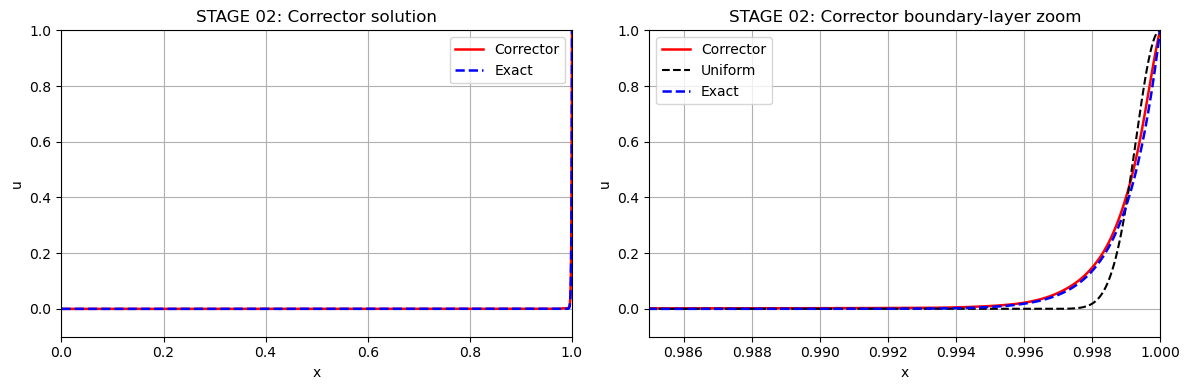

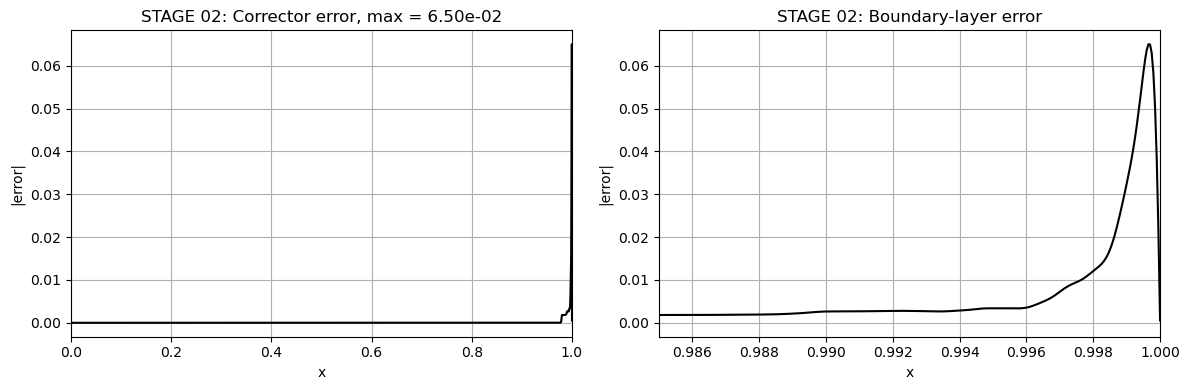

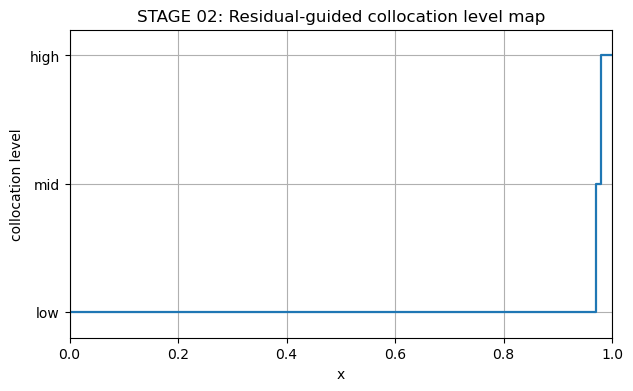

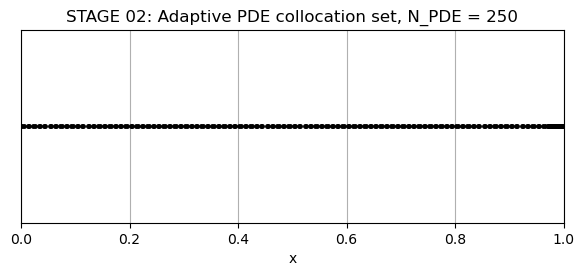

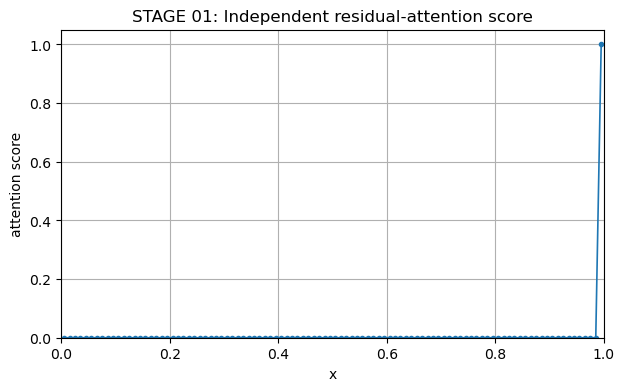

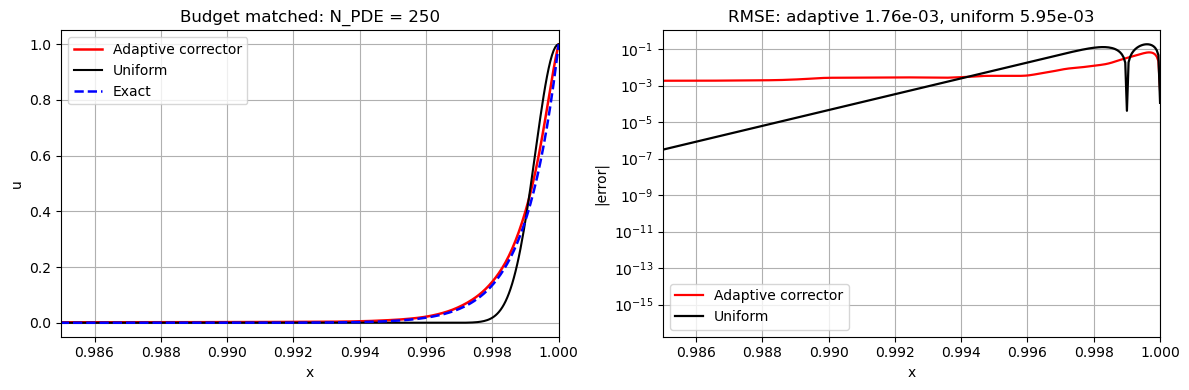

In [7]:
x_zoom_L = max(XL, XR - 15 * nu)
x_cent = 0.5 * (x_edges[:-1] + x_edges[1:])

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(x_plot,u_adapt,'r-',lw=1.8,label='Corrector'); ax[0].plot(x_plot,u_ex,'b--',lw=1.8,label='Exact')
ax[0].grid(True); ax[0].set_xlim(XL,XR); ax[0].set_ylim(-0.1,1); ax[0].set_xlabel('x'); ax[0].set_ylabel('u'); ax[0].legend(); ax[0].set_title('STAGE 02: Corrector solution')
ax[1].plot(x_plot,u_adapt,'r-',lw=1.8,label='Corrector'); ax[1].plot(x_plot,u_uniform,'k--',lw=1.5,label='Uniform'); ax[1].plot(x_plot,u_ex,'b--',lw=1.8,label='Exact')
ax[1].grid(True); ax[1].set_xlim(x_zoom_L,XR); ax[1].set_ylim(-0.1,1); ax[1].set_xlabel('x'); ax[1].set_ylabel('u'); ax[1].legend(); ax[1].set_title('STAGE 02: Corrector boundary-layer zoom')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(x_plot,np.abs(errA),'k-',lw=1.5); ax[0].grid(True); ax[0].set_xlim(XL,XR); ax[0].set_xlabel('x'); ax[0].set_ylabel('|error|'); ax[0].set_title(f'STAGE 02: Corrector error, max = {maxerr_adaptive:.2e}')
ax[1].plot(x_plot,np.abs(errA),'k-',lw=1.5); ax[1].grid(True); ax[1].set_xlim(x_zoom_L,XR); ax[1].set_xlabel('x'); ax[1].set_ylabel('|error|'); ax[1].set_title('STAGE 02: Boundary-layer error')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4)); plt.step(x_edges,np.r_[level_map,level_map[-1]],where='post',lw=1.6); plt.grid(True); plt.xlim(XL,XR); plt.ylim(.8,3.2); plt.yticks([1,2,3],['low','mid','high']); plt.xlabel('x'); plt.ylabel('collocation level'); plt.title('STAGE 02: Residual-guided collocation level map'); plt.show()
plt.figure(figsize=(7,2.5)); plt.plot(xP_adapt,np.zeros_like(xP_adapt),'.k',ms=5); plt.grid(True); plt.xlim(XL,XR); plt.ylim(-.5,.5); plt.yticks([]); plt.xlabel('x'); plt.title(f'STAGE 02: Adaptive PDE collocation set, N_PDE = {Np_adapt}'); plt.show()
plt.figure(figsize=(7,4)); plt.plot(x_cent,attention_score,'-o',lw=1.2,ms=3); plt.grid(True); plt.xlim(XL,XR); plt.ylim(0,1.05); plt.xlabel('x'); plt.ylabel('attention score'); plt.title('STAGE 01: Independent residual-attention score'); plt.show()

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(x_plot,u_adapt,'r-',lw=1.8,label='Adaptive corrector'); ax[0].plot(x_plot,u_uniform,'k-',lw=1.5,label='Uniform'); ax[0].plot(x_plot,u_ex,'b--',lw=1.8,label='Exact'); ax[0].grid(True); ax[0].set_xlim(x_zoom_L,XR); ax[0].set_xlabel('x'); ax[0].set_ylabel('u'); ax[0].legend(); ax[0].set_title(f'Budget matched: N_PDE = {Np_adapt}')
ax[1].semilogy(x_plot,np.maximum(np.abs(errA),1e-16),'r-',lw=1.6,label='Adaptive corrector'); ax[1].semilogy(x_plot,np.maximum(np.abs(errU),1e-16),'k-',lw=1.6,label='Uniform'); ax[1].grid(True); ax[1].set_xlim(x_zoom_L,XR); ax[1].set_xlabel('x'); ax[1].set_ylabel('|error|'); ax[1].legend(); ax[1].set_title(f'RMSE: adaptive {rmse_adaptive:.2e}, uniform {rmse_uniform:.2e}')
plt.tight_layout(); plt.show()